# 6. Which structure changes affect recovery?

Do connection changes, whole-unit replacement, or both add recovery error?

Train the separate-candidate method for 50,000 examples. Copy each trained network for every condition.
Reverse half the target output signs, exactly as in notebook 4.
Keep all target hidden weights and all magnitudes fixed.

First permit neither operation, only connection changes, only whole-unit replacement, or both operations.
Connection changes include candidate replacement, promotion, and active connection removal.
Whole-unit replacement also replaces the selected unit's connections, as required by that operation.
Each comparison between neighboring conditions changes one permission.

A further control permits candidate replacement and promotion but protects every active connection.
It differs from connection changes alone only in whether active connections can be removed.
No units are replaced in this control. Every condition continues to update weights and step sizes.

All cases use the same five seeds, trained states, targets, and examples.
The full curves distinguish the initial error peak from the later return to low error.

Connection changes reduce mean RMSE over the first 10,000 examples after the change from 0.440 to 0.389.
They raise mean RMSE over the next 10,000 examples from 0.188 to 0.229.
Unit replacement has little effect on these means. Results vary across seeds.

With active connections protected, mean RMSE over those same intervals is 0.379 and 0.218.
Thus, new promotions can cause the later delay without lost connections.
Across all 50,000 post-change examples, the means remain close, from 0.219 to 0.221.
Fixed connections do not have a clear overall advantage here.


In [1]:
from phd.sandbox.unit_search.connection_slots import methods as m

assert m.jax.default_backend() == 'gpu'
%matplotlib inline


/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [2]:
results = m.run_recovery_parts()


fixed: post-change RMSE 0.219


connections_only: post-change RMSE 0.219


units_only: post-change RMSE 0.219


both: post-change RMSE 0.220


candidates_only: post-change RMSE 0.221


58.1s for 5 seeds per condition


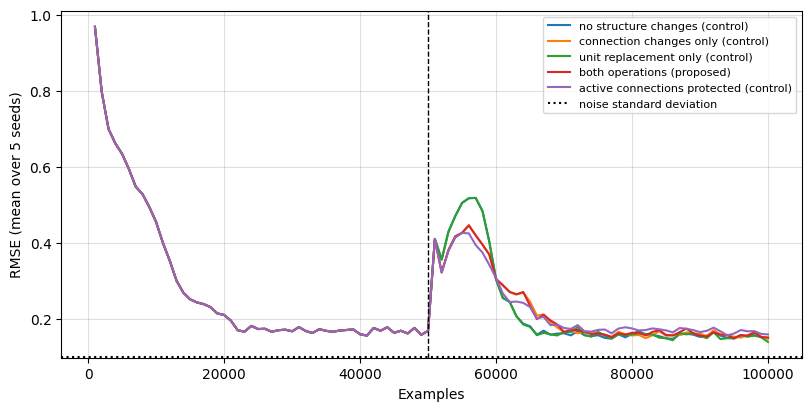

In [3]:
labels = {'fixed': 'no structure changes (control)',
          'connections_only': 'connection changes only (control)',
          'units_only': 'unit replacement only (control)',
          'both': 'both operations (proposed)',
          'candidates_only': 'active connections protected (control)'}
m.plot(results, changed=True, labels=labels)
